# One hidden layered ANN implementation from scratch
(3 layer total)

In [14]:
import numpy as np
import matplotlib.pyplot as plt

In [15]:
#Activation Functions
def sigmoid(x):
  """1 / (1 + e^-x)"""
  return 1 / (1 + np.exp(-np.clip(x, -500, 500)))

def relu(x):
  """max(0, x)"""
  return np.maximum(0, x)

def tanh(x):
  return np.tanh(x)

def linear(x):
  return x

#Activation Derivatives
def sigmoid_derivative(x):
  """f(x) * (1 - f(x))"""
  s = sigmoid(x)
  return s * (1 - s)

def relu_derivative(x):
  """1 if x > 0 else 0"""
  return np.where(x > 0, 1.0, 0.0)

def tanh_derivative(x):
  """1 - tanh^2(x)"""
  return 1.0 - np.tanh(x) ** 2

def linear_derivative(x):
  return np.ones_like(x)

#Loss Functions
def mse(y_true, y_pred):
  return np.mean((y_pred - y_true) ** 2)

def mae(y_true, y_pred):
  return np.mean(np.abs(y_pred - y_true))

#Loss Derivatives with respect to y_pred
def mse_derivative(y_true, y_pred):
  """d(MSE)/dy_pred = 2 * (y_pred - y_true) / N"""
  n = y_true.shape[0]
  return 2 * (y_pred - y_true) / n

def mae_derivative(y_true, y_pred):
  """d(MAE)/dy_pred = sign(y_pred - y_true) / N"""
  n = y_true.shape[0]
  return np.sign(y_pred - y_true) / n

In [16]:
class One_hidden_layered_ANN:
  def __init__(self, input_size, hidden_size, output_size):
    self.input_size = input_size
    self.hidden_size = hidden_size
    self.output_size = output_size

    # Xavier/Glorot-like initialization for better convergence
    self.weights_input_hidden = np.random.randn(self.input_size, self.hidden_size) * np.sqrt(2.0 / (self.input_size + self.hidden_size))
    self.bias_hidden = np.zeros((1, self.hidden_size))
    self.weights_hidden_output = np.random.randn(self.hidden_size, self.output_size) * np.sqrt(2.0 / (self.hidden_size + self.output_size))
    self.bias_output = np.zeros((1, self.output_size))

  def forward_pass(self, X, hidden_activation, output_activation):
    # Input to hidden layer
    self.z1 = np.dot(X, self.weights_input_hidden) + self.bias_hidden
    self.a1 = hidden_activation(self.z1)

    # Hidden to output layer
    self.z2 = np.dot(self.a1, self.weights_hidden_output) + self.bias_output
    self.a2 = output_activation(self.z2)
    return self.a2

  def weight_update(self, X, y, learning_rate, hidden_deriv, output_deriv, loss_deriv):
    m = X.shape[0]

    # Output layer error and gradients
    da2 = loss_deriv(y, self.a2)
    dz2 = da2 * output_deriv(self.z2)
    dw2 = np.dot(self.a1.T, dz2) / m
    db2 = np.sum(dz2, axis=0, keepdims=True) / m

    # Hidden layer error and gradients
    da1 = np.dot(dz2, self.weights_hidden_output.T)
    dz1 = da1 * hidden_deriv(self.z1)
    dw1 = np.dot(X.T, dz1) / m
    db1 = np.sum(dz1, axis=0, keepdims=True) / m

    # Gradient descent update
    self.weights_hidden_output -= learning_rate * dw2
    self.bias_output -= learning_rate * db2
    self.weights_input_hidden -= learning_rate * dw1
    self.bias_hidden -= learning_rate * db1

  def train(self, X, y, epochs, learning_rate, hidden_activation_function, output_activation_function, error_function):
    act_funcs = {
        'sigmoid': (sigmoid, sigmoid_derivative),
        'relu': (relu, relu_derivative),
        'tanh': (tanh, tanh_derivative),
        'linear': (linear, linear_derivative)
    }

    loss_funcs = {
        'mse': (mse, mse_derivative),
        'mae': (mae, mae_derivative)
    }

    h_act, h_deriv = act_funcs[hidden_activation_function]
    o_act, o_deriv = act_funcs[output_activation_function]
    loss_fn, loss_deriv = loss_funcs[error_function]

    self.history = []
    for epoch in range(epochs):
      y_pred = self.forward_pass(X, h_act, o_act)
      loss = loss_fn(y, y_pred)
      self.history.append(loss)

      self.weight_update(X, y, learning_rate, h_deriv, o_deriv, loss_deriv)

      if (epoch + 1) % max(1, epochs // 10) == 0 or epoch == epochs - 1:
        print(f"Epoch {epoch+1}/{epochs} - Loss ({error_function}): {loss:.6f}")

  def predict(self, X, hidden_activation_function='sigmoid', output_activation_function='linear'):
    act_funcs = {
        'sigmoid': sigmoid,
        'relu': relu,
        'tanh': tanh,
        'linear': linear
    }
    h_act = act_funcs[hidden_activation_function]
    o_act = act_funcs[output_activation_function]
    return self.forward_pass(X, h_act, o_act)

  def evaluate(self, X, y, error_function='mse', hidden_activation_function='sigmoid', output_activation_function='linear'):
    loss_funcs = {
        'mse': mse,
        'mae': mae
    }
    y_pred = self.predict(X, hidden_activation_function, output_activation_function)
    return loss_funcs[error_function](y, y_pred)

### 1. Training the logical AND Gate

=== Training AND Gate ===
Epoch 1000/10000 - Loss (mse): 0.125090
Epoch 2000/10000 - Loss (mse): 0.040905
Epoch 3000/10000 - Loss (mse): 0.014312
Epoch 4000/10000 - Loss (mse): 0.007296
Epoch 5000/10000 - Loss (mse): 0.004588
Epoch 6000/10000 - Loss (mse): 0.003245
Epoch 7000/10000 - Loss (mse): 0.002467
Epoch 8000/10000 - Loss (mse): 0.001969
Epoch 9000/10000 - Loss (mse): 0.001626
Epoch 10000/10000 - Loss (mse): 0.001378

Predictions for AND Gate:
Input: [0 0] -> Target: 0 -> Predicted: 0.0006
Input: [0 1] -> Target: 0 -> Predicted: 0.0351
Input: [1 0] -> Target: 0 -> Predicted: 0.0347
Input: [1 1] -> Target: 1 -> Predicted: 0.9445


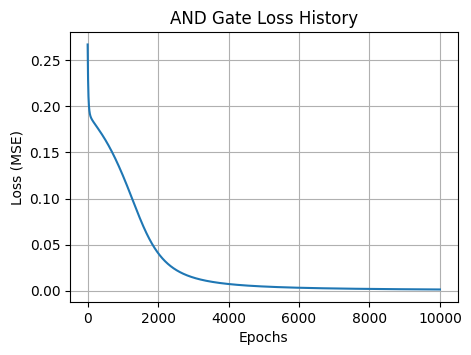

In [17]:
# Train and predict for AND gate
print("=== Training AND Gate ===")
ann_and = One_hidden_layered_ANN(input_size=2, hidden_size=4, output_size=1)
ann_and.train(X, y_and, epochs=10000, learning_rate=0.5,
              hidden_activation_function='sigmoid',
              output_activation_function='sigmoid',
              error_function='mse')

preds_and = ann_and.predict(X, 'sigmoid', 'sigmoid')
print("\nPredictions for AND Gate:")
for inputs, target, pred in zip(X, y_and, preds_and):
    print(f"Input: {inputs} -> Target: {target[0]} -> Predicted: {pred[0]:.4f}")

plt.figure(figsize=(5, 3.5))
plt.plot(ann_and.history, color='tab:blue')
plt.title("AND Gate Loss History")
plt.xlabel("Epochs")
plt.ylabel("Loss (MSE)")
plt.grid(True)
plt.show()

### 2. Training the logical OR Gate

=== Training OR Gate ===
Epoch 1000/10000 - Loss (mse): 0.059053
Epoch 2000/10000 - Loss (mse): 0.014505
Epoch 3000/10000 - Loss (mse): 0.006522
Epoch 4000/10000 - Loss (mse): 0.003907
Epoch 5000/10000 - Loss (mse): 0.002700
Epoch 6000/10000 - Loss (mse): 0.002027
Epoch 7000/10000 - Loss (mse): 0.001606
Epoch 8000/10000 - Loss (mse): 0.001320
Epoch 9000/10000 - Loss (mse): 0.001115
Epoch 10000/10000 - Loss (mse): 0.000962

Predictions for OR Gate:
Input: [0 0] -> Target: 0 -> Predicted: 0.0460
Input: [0 1] -> Target: 1 -> Predicted: 0.9721
Input: [1 0] -> Target: 1 -> Predicted: 0.9695
Input: [1 1] -> Target: 1 -> Predicted: 0.9955


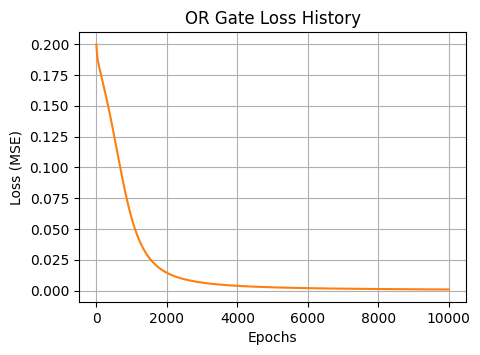

In [18]:
# Train and predict for OR gate
print("=== Training OR Gate ===")
ann_or = One_hidden_layered_ANN(input_size=2, hidden_size=4, output_size=1)
ann_or.train(X, y_or, epochs=10000, learning_rate=0.5,
             hidden_activation_function='sigmoid',
             output_activation_function='sigmoid',
             error_function='mse')

preds_or = ann_or.predict(X, 'sigmoid', 'sigmoid')
print("\nPredictions for OR Gate:")
for inputs, target, pred in zip(X, y_or, preds_or):
    print(f"Input: {inputs} -> Target: {target[0]} -> Predicted: {pred[0]:.4f}")

plt.figure(figsize=(5, 3.5))
plt.plot(ann_or.history, color='tab:orange')
plt.title("OR Gate Loss History")
plt.xlabel("Epochs")
plt.ylabel("Loss (MSE)")
plt.grid(True)
plt.show()

### 3. Training the logical XOR Gate

=== Training XOR Gate ===
Epoch 1500/15000 - Loss (mse): 0.249331
Epoch 3000/15000 - Loss (mse): 0.243429
Epoch 4500/15000 - Loss (mse): 0.202755
Epoch 6000/15000 - Loss (mse): 0.124543
Epoch 7500/15000 - Loss (mse): 0.038818
Epoch 9000/15000 - Loss (mse): 0.015344
Epoch 10500/15000 - Loss (mse): 0.008531
Epoch 12000/15000 - Loss (mse): 0.005663
Epoch 13500/15000 - Loss (mse): 0.004153
Epoch 15000/15000 - Loss (mse): 0.003241

Predictions for XOR Gate:
Input: [0 0] -> Target: 0 -> Predicted: 0.0608
Input: [0 1] -> Target: 1 -> Predicted: 0.9432
Input: [1 0] -> Target: 1 -> Predicted: 0.9471
Input: [1 1] -> Target: 0 -> Predicted: 0.0569


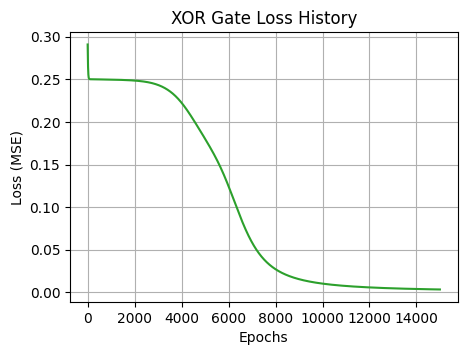

In [19]:
# Train and predict for XOR gate
print("=== Training XOR Gate ===")
ann_xor = One_hidden_layered_ANN(input_size=2, hidden_size=4, output_size=1)
ann_xor.train(X, y_xor, epochs=15000, learning_rate=0.5,
              hidden_activation_function='sigmoid',
              output_activation_function='sigmoid',
              error_function='mse')

preds_xor = ann_xor.predict(X, 'sigmoid', 'sigmoid')
print("\nPredictions for XOR Gate:")
for inputs, target, pred in zip(X, y_xor, preds_xor):
    print(f"Input: {inputs} -> Target: {target[0]} -> Predicted: {pred[0]:.4f}")

plt.figure(figsize=(5, 3.5))
plt.plot(ann_xor.history, color='tab:green')
plt.title("XOR Gate Loss History")
plt.xlabel("Epochs")
plt.ylabel("Loss (MSE)")
plt.grid(True)
plt.show()